# Proyek Analisis Data: [Bike-sharing-dataset]
- **Nama:** [Andira Farras Syafiq]
- **Email:** [andirafarrassyafiq@gmail.com]
- **ID Dicoding:** [andira_farras_sygm6j]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Musim apa yang memiliki rata-rata jumlah peminjaman sepeda harian paling tinggi sepanjang tahun 2011–2012?
- **Pertanyaan 2:** Bagaimana perbandingan rata-rata jumlah peminjaman sepeda harian antara hari kerja (workingday = 1) dan hari libur/akhir pekan (workingday = 0) selama 2011–2012?

## Import Semua Packages/Library yang Digunakan

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load both day_df and hour_day to examine whether the data can be loaded or not

In [4]:
day_df = pd.read_csv('day.csv')
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [5]:
hour_df = pd.read_csv('hour.csv')
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Assessing Data

#### Identifying problem on both datas, I checked for missing value, invalid value, duplicate data, inconsistent value, and inaccurate value

In [6]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [7]:
day_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [8]:

day_df.duplicated().sum()

np.int64(0)

In [9]:

day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [10]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [11]:
hour_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [12]:
hour_df.duplicated().sum()

np.int64(0)

In [13]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
- Setelah dilihat datanya tidak ada yang null, jumlahnya sama, tidak ada duplicate, dan statistiknya normal
- Menghilangkan missing value
- Terdapat kesalahan tipe data untuk dteday karena harusnya datetime64 karena bertipe waktu, selanjutnya akan dibenarkan tipe datanya
- Data seperti nama musim diwakilkan oleh angka, ini nantinya akan bermasalah di bagian visualisasi
- Cleaning data agar lebih gampang dipahami, seperti menghapus kolom yang tidak diperlukan di proses analisis dan memperbaiki nama-nama dalam data

### Cleaning Data

#### Fixing the type of the data, clean the column of the data (seperti rename data yang kualitatif namun diwakili angka agar gampang dibaca dan menghilangkan missing value)

In [14]:
datetime_columns = ["dteday"]
for column in datetime_columns:
    day_df[column] = pd.to_datetime(day_df[column])
    hour_df[column] = pd.to_datetime(hour_df[column])

    day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), floa

In [15]:
drop_cols = ["casual", "registered", "instant", "temp", "atemp", "hum", "windspeed", "weathersit"]
hour_df.drop(drop_cols, axis=1, inplace=True)
day_df.drop(drop_cols, axis=1, inplace=True)
day_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,cnt
0,2011-01-01,1,0,1,0,6,0,985
1,2011-01-02,1,0,1,0,0,0,801
2,2011-01-03,1,0,1,0,1,1,1349
3,2011-01-04,1,0,1,0,2,1,1562
4,2011-01-05,1,0,1,0,3,1,1600


In [16]:
rename_df = {"yr": "year", "mnth": "month", "hr": "hour"}
hour_df.rename(columns=rename_df, inplace=True)
day_df.rename(columns=rename_df, inplace=True)
day_df.head()

,dteday,season,year,month,holiday,weekday,workingday,cnt
0,2011-01-01,1,0,1,0,6,0,985
1,2011-01-02,1,0,1,0,0,0,801
2,2011-01-03,1,0,1,0,1,1,1349
3,2011-01-04,1,0,1,0,2,1,1562
4,2011-01-05,1,0,1,0,3,1,1600


In [17]:
season_df = {
    1: "spring",
    2: "summer",
    3: "fall",
    4: "winter"
}
hour_df["season"] = hour_df["season"].map(season_df)
day_df["season"] = day_df["season"].map(season_df)

In [18]:
working_day_df = {
    0: "weekend",
    1: "workingday"
}
hour_df["workingday"] = hour_df["workingday"].map(working_day_df)
day_df["workingday"] = day_df["workingday"].map(working_day_df)

## Exploratory Data Analysis (EDA)

### Explore the data, mencari data yang dapat digunakan untuk menjawab pertanyaan bisnis. Di sini digunakan data merge antara hour dan day.Kemudian meng-aggregat data.

In [19]:
main_df = pd.merge(hour_df, day_df, on="dteday")
main_df.head()

,dteday,season_x,year_x,month_x,hour,holiday_x,weekday_x,workingday_x,cnt_x,season_y,year_y,month_y,holiday_y,weekday_y,workingday_y,cnt_y
0,2011-01-01,spring,0,1,0,0,6,weekend,16,spring,0,1,0,6,weekend,985
1,2011-01-01,spring,0,1,1,0,6,weekend,40,spring,0,1,0,6,weekend,985
2,2011-01-01,spring,0,1,2,0,6,weekend,32,spring,0,1,0,6,weekend,985
3,2011-01-01,spring,0,1,3,0,6,weekend,13,spring,0,1,0,6,weekend,985
4,2011-01-01,spring,0,1,4,0,6,weekend,1,spring,0,1,0,6,weekend,985


In [20]:
main_df.describe(include="all")

,dteday,season_x,year_x,month_x,hour,holiday_x,weekday_x,workingday_x,cnt_x,season_y,year_y,month_y,holiday_y,weekday_y,workingday_y,cnt_y
count,17379,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379,17379.000000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379,17379.000000
unique,NaN,4,NaN,NaN,NaN,NaN,NaN,2,NaN,4,NaN,NaN,NaN,NaN,2,NaN
top,NaN,fall,NaN,NaN,NaN,NaN,NaN,workingday,NaN,fall,NaN,NaN,NaN,NaN,workingday,NaN
freq,NaN,4496,NaN,NaN,NaN,NaN,NaN,11865,NaN,4496,NaN,NaN,NaN,NaN,11865,NaN
mean,2012-01-02 04:08:34.552045568,NaN,0.502561,6.537775,11.546752,0.028770,3.003683,NaN,189.463088,NaN,0.502561,6.537775,0.028770,3.003683,NaN,4533.692963
min,2011-01-01 00:00:00,NaN,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,1.000000,NaN,0.000000,1.000000,0.000000,0.000000,NaN,22.000000
25%,2011-07-04 00:00:00,NaN,0.000000,4.000000,6.000000,0.000000,1.000000,NaN,40.000000,NaN,0.000000,4.000000,0.000000,1.000000,NaN,3214.000000
50%,2012-01-02 00:00:00,NaN,1.000000,7.000000,12.000000,0.000000,3.000000,NaN,142.000000,NaN,1.000000,7.000000,0.000000,3.000000,NaN,4563.000000
75%,2012-07-02 00:00:00,NaN,1.000000,10.000000,18.000000,0.000000,5.000000,NaN,281.000000,NaN,1.000000,10.000000,0.000000,5.000000,NaN,5986.000000
max,2012-12-31 00:00:00,NaN,1.000000,12.000000,23.000000,1.000000,6.000000,NaN,977.000000,NaN,1.000000,12.000000,1.000000,6.000000,NaN,8714.000000


In [21]:
season_df = day_df.groupby(by="season").agg({
    "cnt": "mean"
}).reset_index()

In [22]:
season_df = season_df.sort_values(by="cnt", ascending=False)
season_df.head()

,season,cnt
0,fall,5644.303191
2,summer,4992.331522
3,winter,4728.162921
1,spring,2604.132597


In [23]:
perbandingan_hari_df = day_df.groupby(by="workingday").agg({
    "cnt":"mean"
}).reset_index()

In [24]:
perbandingan_hari_df = perbandingan_hari_df.sort_values(by="cnt", ascending=False)
perbandingan_hari_df.head()

,workingday,cnt
1,workingday,4584.820000
0,weekend,4330.168831


## Visualization & Explanatory Analysis

### Pertanyaan 1: Musim apa yang memiliki rata-rata jumlah peminjaman sepeda harian paling tinggi sepanjang tahun 2011–2012?

<Axes: xlabel='season', ylabel='cnt'>

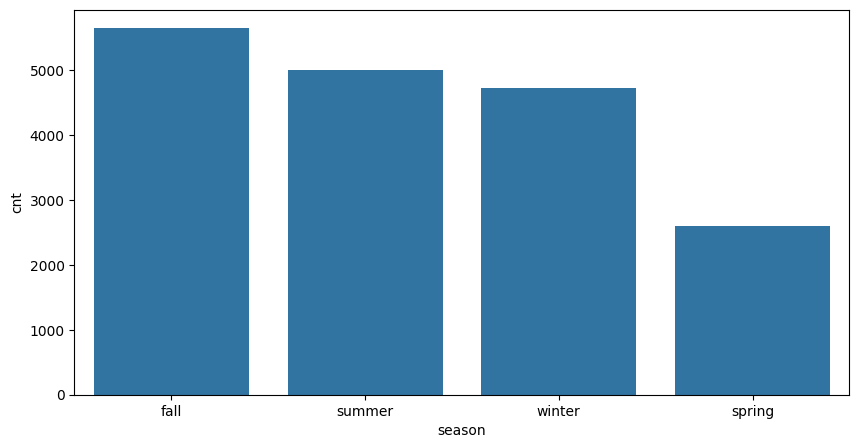

In [25]:
plt.figure(figsize=(10, 5))
sns.barplot(x="season", y="cnt", data=season_df)

### Pertanyaan 2: Bagaimana perbandingan rata-rata jumlah peminjaman sepeda harian antara hari kerja (workingday = 1) dan hari libur/akhir pekan (workingday = 0) selama 2011–2012?

<Axes: xlabel='workingday', ylabel='cnt'>

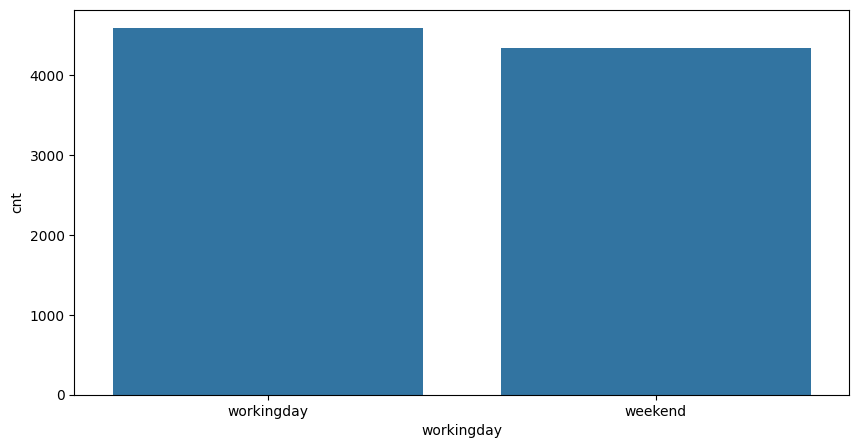

In [26]:
plt.figure(figsize=(10, 5))
sns.barplot(x="workingday", y="cnt", data=perbandingan_hari_df)

**Insight:** (Opsional)
- Dari grafik di atas, dapat diketahui bahwa musim gugur memiliki rata-rata jumlah peminjaman sepeda harian paling tinggi sepanjang tahun 2011–2012.
- Dari grafik di atas, dapat diketahui bahwa rata-rata peminjaman sepeda harian lebih tinggi pada hari kerja (workingday = 1) dibandingkan dengan hari libur/akhir pekan (workingday = 0) selama tahun 2011–2012.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Musim gugur memiliki rata-rata jumlah peminjaman sepeda harian paling tinggi sepanjang tahun 2011–2012. Di musim gugur (fall), rata-rata peminjaman sepeda harian tercatat di angka 5.644 peminjaman, sedangkan musim semi (spring) terendah dan berada di angka 2.604 peminjaman.
- **Conclusion pertanyaan 2:** Rata-rata peminjaman sepeda harian lebih tinggi pada hari kerja selama tahun 2011–2012. Rata-rata peminjaman harian pada hari kerja (workingday) tercatat berada di angka 4.584 peminjaman, dibandingkan dengan hari libur/akhir pekan (weekend) yang mencatatkan 4.330 peminjaman.

**Rekomendasi Action Item:**
- Menambah jumlah sepeda yang dapat dipinjam, terutama pada musim gugur dan pada hari kerja untuk mempersiapkan pertambahan demand pasar
- Memberikan diskon bagi pekerja sehingga menumbuhkan loyalitas pada brand

In [27]:
main_df.to_csv("main_df.csv", index=False)